<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/MRAM_Bit_Switch_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
try:
    import google.colab
    import IPython
except ImportError:
    pass
else:
    IPython.get_ipython().system('uv pip install mumaxplus pillow')

In [ ]:
"""This script switches the state of a bit in a vertical MRAM stack (free layer
on the bottom, spacer layer, fixed layer on top) using Slonczewski spin transfer
torque. This is based on both the paper "The design and verification of MuMax3"
https://doi.org/10.1063/1.4899186 and on session 3 example 3 of the MuMax3
workshop https://mumax.ugent.be/mumax3-workshop/ ."""

from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import Ellipse, get_rgb

plt.rcParams['figure.dpi'] = 200

# --- set up the world ---
length, width, thickness = 160e-9, 80e-9, 5e-9
nx, ny, nz = 64, 32, 1
cx, cy, cz = length/nx, width/ny, thickness/nz
world = World(cellsize=(cx, cy, cz))

# --- set up ferromagnet ---
geometry = Ellipse(length, width)
# translate to the center of the simulation box ((0,0,0) is center of first cell)
geometry.translate(length/2 - cx/2, width/2 - cy/2, thickness/2 - cz/2)

magnet = Ferromagnet(world, Grid((nx, ny, nz)), geometry=geometry)
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.01
magnet.magnetization = (1, 0, 0)
magnet.minimize()

# add polarized current and fixed FM layer
magnet.pol = 0.5669
magnet.Lambda = 2
magnet.epsilon_prime = 1
area = length * width * np.pi / 4
magnet.jcur = (0, 0, -4e-3/area)  # -4 mA

theta = 20 * np.pi / 180
magnet.fixed_layer = (np.cos(theta), np.sin(theta), 0)

# --- schedule the output ---
tmax = 0.5e-9
timepoints = np.linspace(0, tmax, 151)
outputquantities = {"mx": lambda: magnet.magnetization.average()[0],
                    "my": lambda: magnet.magnetization.average()[1],
                    "mz": lambda: magnet.magnetization.average()[2],
                    "rgb": lambda: get_rgb(magnet.magnetization, layer=0)}

# --- run the solver ---
output = world.timesolver.solve(timepoints, outputquantities)

# --- plot <m> in time ---
fig, ax = plt.subplots(figsize=(8, 5))
for key in ["mx", "my", "mz"]:
    ax.plot(timepoints*1e9, output[key], '-', label=key)

# make plot pretty
ax.set_title("Elliptical MRAM bit switch")
ax.set_xlim(0, tmax*1e9)
ax.set_ylim(-1, 1)
ax.set_xlabel("time $t$ (ns)")
ax.set_ylabel("<m>")
ax.legend()
ax.grid()
fig.tight_layout()
plt.show()

# -- animate magnetization rgb ---
fig, ax = plt.subplots(figsize=(6.4, 4))

extent = np.asarray([-0.5*cx, length - 0.5*cx, -0.5*cy, width - 0.5*cy]) * 1e9
im = ax.imshow(output["rgb"][0], origin="lower", extent=extent)
ax.set_xlabel("$x$ (nm)")
ax.set_ylabel("$y$ (nm)")
fig.tight_layout()

def plot_frame(i):
    im.set_data(output["rgb"][i])
    ax.set_title(f"$t$ = {output['time'][i]*1e9:.3f} ns")
    return [im]

fps = 15
repeat_delay = 5000/fps
anim = FuncAnimation(fig, plot_frame, frames=len(output["time"]),
                     interval=1000/fps, repeat_delay=repeat_delay)

plt.close(fig) # Prevents rendering a static duplicate frame
HTML(anim.to_jshtml())

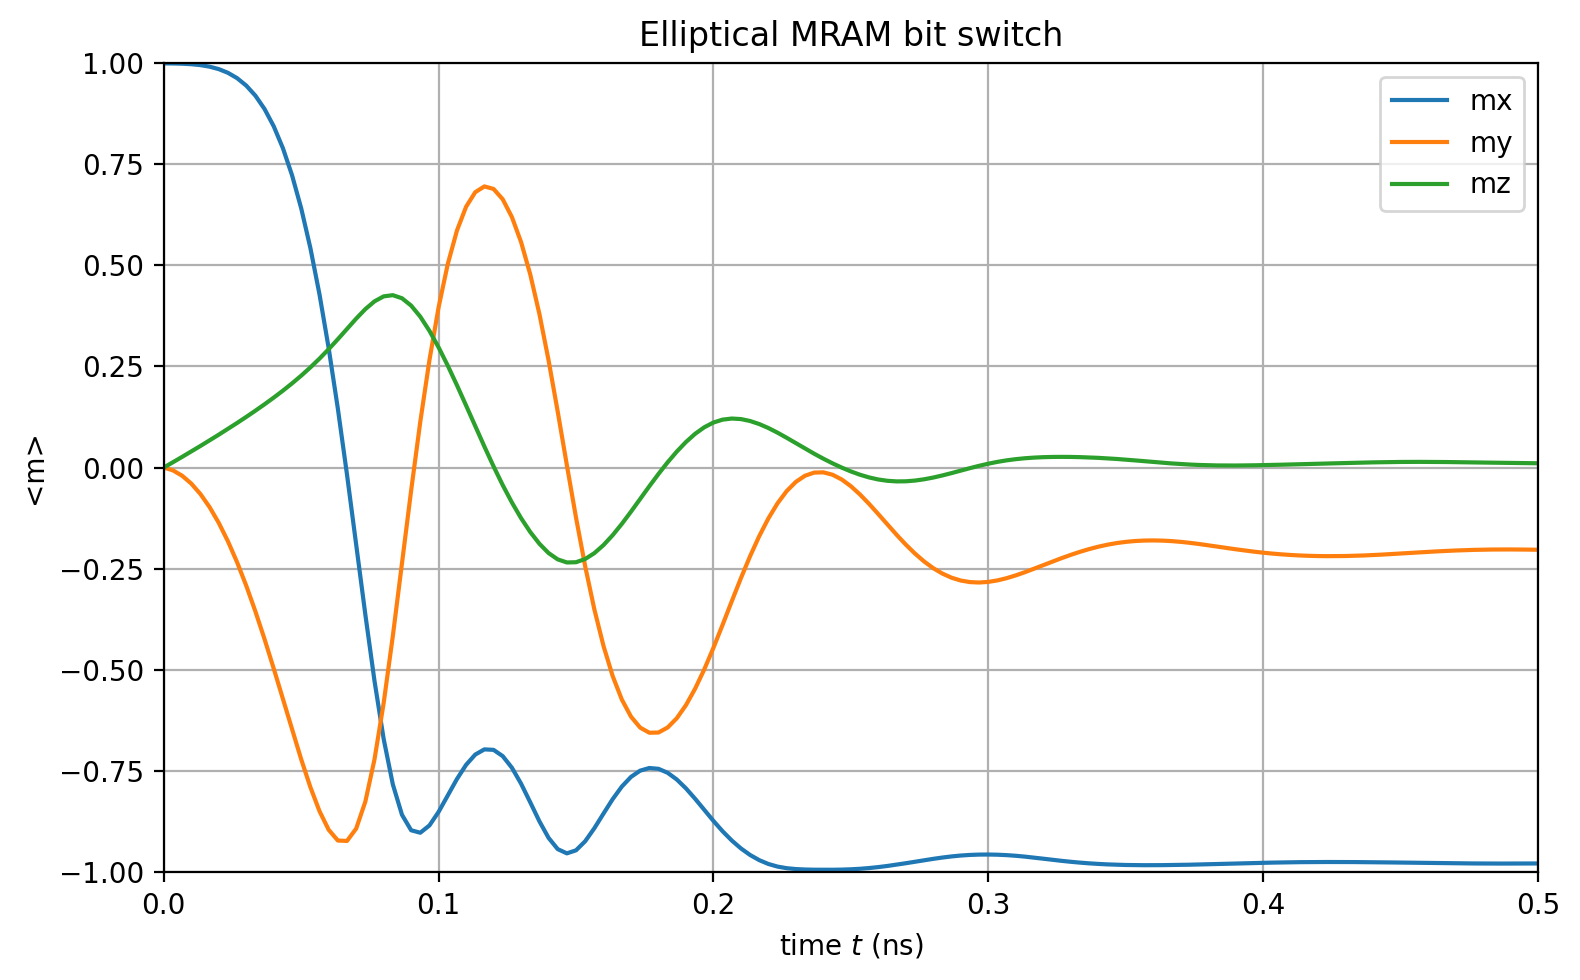

In [ ]:
"""This script switches the state of a bit in a vertical MRAM stack (free layer
on the bottom, spacer layer, fixed layer on top) using Slonczewski spin transfer
torque."""

from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import Ellipse

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['figure.dpi'] = 200
plt.rcParams['animation.embed_limit'] = 100.0

# Control knobs
length_m = 160e-9
width_m = 80e-9
thickness_m = 5e-9
nx, ny, nz = 64, 32, 1
msat_val = 800e3
aex_val = 13e-12
alpha_val = 0.01
pol_val = 0.5669
lambda_val = 2
epsilon_prime_val = 1
current_amps = -4e-3
theta_deg = 20
tmax_s = 0.5e-9
time_steps = 151
fps_val = 15
quiver_arrow_scale = 1.0
magnetization_color_direction = 'mz'

# Set up the world
cx, cy, cz = length_m / nx, width_m / ny, thickness_m / nz
world = World(cellsize=(cx, cy, cz))

# Set up ferromagnet
geometry = Ellipse(length_m, width_m)
geometry.translate(length_m / 2 - cx / 2, width_m / 2 - cy / 2, thickness_m / 2 - cz / 2)

magnet = Ferromagnet(world, Grid((nx, ny, nz)), geometry=geometry)
magnet.msat = msat_val
magnet.aex = aex_val
magnet.alpha = alpha_val
magnet.magnetization = (1, 0, 0)
magnet.minimize()

magnet.pol = pol_val
magnet.Lambda = lambda_val
magnet.epsilon_prime = epsilon_prime_val
area = length_m * width_m * np.pi / 4
magnet.jcur = (0, 0, current_amps / area)

theta = theta_deg * np.pi / 180
magnet.fixed_layer = (np.cos(theta), np.sin(theta), 0)

# Schedule the output
timepoints = np.linspace(0, tmax_s, time_steps)
outputquantities = {
    "mx": lambda: magnet.magnetization.average()[0],
    "my": lambda: magnet.magnetization.average()[1],
    "mz": lambda: magnet.magnetization.average()[2],
    "m_field": lambda: magnet.magnetization.get().copy()
}

# Run the solver
output = world.timesolver.solve(timepoints, outputquantities)

# Plot <m> in time
fig, ax = plt.subplots(figsize=(8, 5))
for key in ["mx", "my", "mz"]:
    ax.plot(timepoints * 1e9, output[key], '-', label=key)

ax.set_title("Elliptical MRAM bit switch")
ax.set_xlim(0, tmax_s * 1e9)
ax.set_ylim(-1, 1)
ax.set_xlabel("time $t$ (ns)")
ax.set_ylabel("<m>")
ax.legend()
ax.grid()
fig.tight_layout()
plt.show()

# Animate magnetization vector field glyphs
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.set_xlabel("$x$ (nm)")
ax.set_ylabel("$y$ (nm)")

x_coords = np.arange(nx) * cx * 1e9
y_coords = np.arange(ny) * cy * 1e9
X, Y = np.meshgrid(x_coords, y_coords, indexing='ij')

ax.set_xlim(-cx * 0.5 * 1e9, length_m * 1e9 + cx * 0.5 * 1e9)
ax.set_ylim(-cy * 0.5 * 1e9, width_m * 1e9 + cy * 0.5 * 1e9)
ax.set_aspect('equal')
fig.tight_layout()

m_fields = output["m_field"]
U0 = m_fields[0][0, 0, :, :].T
V0 = m_fields[0][1, 0, :, :].T

if magnetization_color_direction == 'mz':
    C0 = m_fields[0][2, 0, :, :].T
elif magnetization_color_direction == 'mx':
    C0 = m_fields[0][0, 0, :, :].T
elif magnetization_color_direction == 'my':
    C0 = m_fields[0][1, 0, :, :].T
else:
    C0 = m_fields[0][2, 0, :, :].T

scale_factor = (1 / (cx * 1e9)) * quiver_arrow_scale
Q = ax.quiver(X, Y, U0, V0, C0, cmap='RdBu', units='xy', scale=scale_factor, pivot='mid')

def plot_frame(i):
    """This script function updates the magnetization vector field glyphs for each animation frame."""
    U = m_fields[i][0, 0, :, :].T
    V = m_fields[i][1, 0, :, :].T

    if magnetization_color_direction == 'mz':
        C = m_fields[i][2, 0, :, :].T
    elif magnetization_color_direction == 'mx':
        C = m_fields[i][0, 0, :, :].T
    elif magnetization_color_direction == 'my':
        C = m_fields[i][1, 0, :, :].T
    else:
        C = m_fields[i][2, 0, :, :].T

    Q.set_UVC(U, V, C)
    ax.set_title(f"$t$ = {output['time'][i] * 1e9:.3f} ns")
    return [Q]

repeat_delay = 5000 / fps_val
anim = FuncAnimation(
    fig, plot_frame, frames=len(output["time"]),
    interval=1000 / fps_val, repeat_delay=repeat_delay, blit=False
)

plt.close(fig)
HTML(anim.to_jshtml())